# Practical 13: K-Means Clustering – Mall Customers

**Aim:** To group customers based on Annual Income and Spending Score using K-Means Clustering.

**Dataset:** [Mall Customer Segmentation – Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)

Download `Mall_Customers.csv` and keep it in the same folder as this notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

In [2]:
# Load data
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


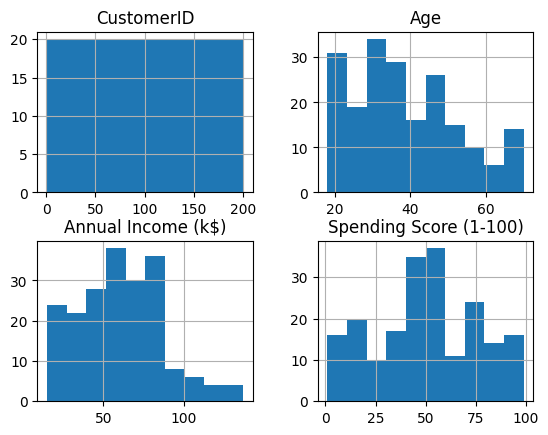

In [3]:
df.hist()
plt.show()

In [4]:
# Select Annual Income and Spending Score
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
X[:3]

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6


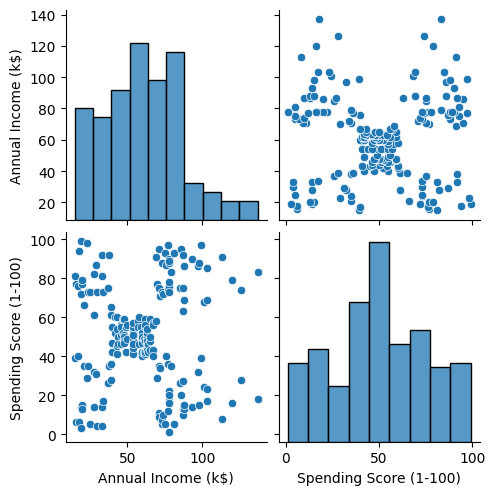

In [5]:
sns.pairplot(X)
plt.show()

In [6]:
# Create KMeans model
model = KMeans(n_clusters=5, random_state=42, n_init=10)
model

KMeans(n_clusters=5, n_init=10, random_state=42)

In [7]:
# Training
model.fit(X)

KMeans(n_clusters=5, n_init=10, random_state=42)

In [8]:
# Output clusters
model.labels_

array([4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 0,
       4, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 1, 0, 1, 3, 1, 3, 1,
       0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1], dtype=int32)

In [9]:
# Cluster centroids
model.cluster_centers_

array([[55.2962963 , 49.51851852],
       [86.53846154, 82.12820513],
       [25.72727273, 79.36363636],
       [88.2       , 17.11428571],
       [26.30434783, 20.91304348]])

In [10]:
# Predict cluster for a new customer
model.predict([[50, 60]])

/Users/aryanchavan24/JupyterProjects/jupyter-env/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([0], dtype=int32)

In [11]:
# Add cluster labels
X = X.copy()
X["Cluster"] = model.labels_
X.head()

,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4


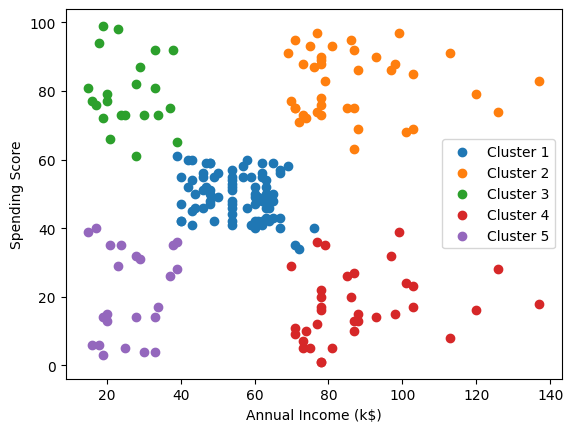

In [12]:
# Plot clusters
for i in range(5):
    cluster = X[X["Cluster"] == i]
    plt.scatter(
        cluster["Annual Income (k$)"],
        cluster["Spending Score (1-100)"],
        label="Cluster " + str(i + 1)
    )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.legend()
plt.show()

In [13]:
# Scale the data
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(
    df[["Annual Income (k$)", "Spending Score (1-100)"]]
)

In [14]:
# Apply KMeans after scaling
km = KMeans(n_clusters=5, random_state=42, n_init=10)
y_pred = km.fit_predict(X_scaled)

y_pred[:10]

array([4, 0, 4, 0, 4, 0, 4, 0, 4, 0], dtype=int32)

In [15]:
# Add predicted clusters
df["Cluster"] = y_pred
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,0
2,3,Female,20,16,6,4
3,4,Female,23,16,77,0
4,5,Female,31,17,40,4


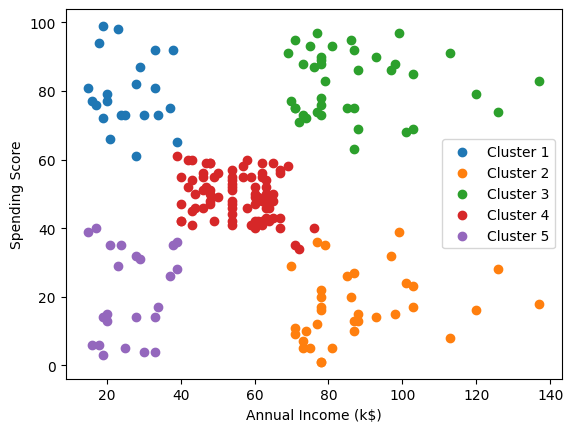

In [16]:
# Plot clusters after scaling
for i in range(5):
    cluster = df[df["Cluster"] == i]
    plt.scatter(
        cluster["Annual Income (k$)"],
        cluster["Spending Score (1-100)"],
        label="Cluster " + str(i + 1)
    )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.legend()
plt.show()

In [17]:
# Check centroids
km.cluster_centers_

array([[0.08792846, 0.79962894],
       [0.6       , 0.16443149],
       [0.58638083, 0.82783883],
       [0.33029751, 0.49508692],
       [0.09265859, 0.20319432]])

In [18]:
# Elbow method
wcss = []

for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

wcss

[23.04072032603991,
 13.993505283127973,
 9.058985215159453,
 6.110312266413656,
 3.5831179059525606,
 3.1003435707513756,
 2.6260623772655114,
 2.2188402609846722,
 1.887272188362091,
 1.692381248570814]

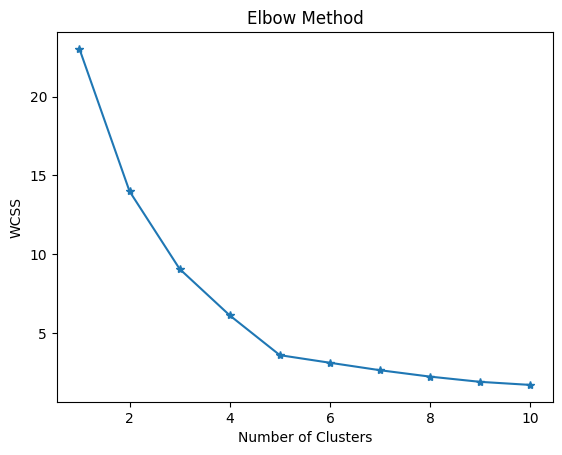

In [19]:
# Elbow graph
plt.plot(range(1, 11), wcss, marker="*")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [20]:
# Silhouette score
from sklearn.metrics import silhouette_score

new = KMeans(n_clusters=5, random_state=42, n_init=10)
new.fit(X_scaled)

silhouette_score(X_scaled, new.labels_)

np.float64(0.5594854531227246)

## Conclusion

K-Means Clustering was implemented on the Mall Customers dataset using Annual Income and Spending Score. Customers were grouped into five clusters. The clusters were visualized, and the Elbow Method and Silhouette Score were used to evaluate the clustering.